# Largest Rectangle in Histogram

Given an array of integers heights representing the histogram's bar height where the width of each bar is 1, return the area of the largest rectangle in the histogram.



Example 1:


Input: heights = [2,1,5,6,2,3]
Output: 10
Explanation: The above is a histogram where width of each bar is 1.
The largest rectangle is shown in the red area, which has an area = 10 units.

In [1]:
class Solution {
    fun largestRectangleArea(heights: IntArray): Int {
        var rightBorder = IntArray(heights.size)
        var leftBorder = IntArray(heights.size)

        rightBorder[heights.size-1] = heights.size
        leftBorder[0] = -1

        for (i in 1..<heights.size) {
            var prevInd = i-1

            while(prevInd >= 0 && heights[prevInd]>=heights[i] ) {
                prevInd = leftBorder[prevInd]
            }

            leftBorder[i] = prevInd
        }

        for (i in heights.size-2 downTo 0) {
            var prevInd = i+1

            while(prevInd < heights.size && heights[prevInd]>=heights[i] ) {
                prevInd = rightBorder[prevInd]
            }

            rightBorder[i] = prevInd
        }

        return heights.asSequence().mapIndexed { index, value ->
            value * (rightBorder[index] - leftBorder[index] - 1)
        }.max()
    }
}

In [2]:
val solution = Solution()

val example1 = solution.largestRectangleArea(intArrayOf(2,1,5,6,2,3))

println(example1)

val example2 = solution.largestRectangleArea(intArrayOf(2,4))

println(example2)

10
4


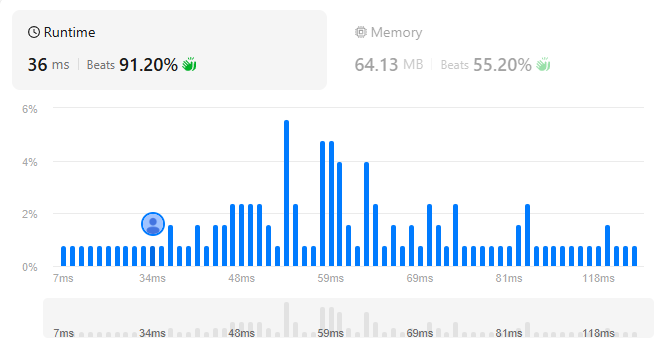